# Day 74: ML Review — Compare All Algorithms on One Dataset

## Objective
- Run 5 algorithms on the same Titanic data, with the same preprocessing and the same folds
- Compare mean AUC and its spread (std) with `cross_val_score`
- Check whether tree-based models agree on which features matter
- Write my own decision guide: "I would use X when... because..." 

> **Data note:** `dataset.csv` is the real Titanic dataset (891 passengers). Target: `Survived`.
> No test set is used to choose between models here, only cross-validation.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

## Theory
- A fair comparison needs **the same data, the same preprocessing, and the same folds** for every model
- Pipelines make that easy: swap only the last step
- **Mean AUC** says how good a model is on average, **std** says how stable it is across folds
- If two models' scores differ by less than the std, the ranking may just be noise
- A big gap between train AUC and CV AUC means **overfitting**
- Tree-based models give `feature_importances_`, which we can compare across models

In [2]:
df = pd.read_csv("dataset.csv")

numeric_cols = ["Age", "SibSp", "Parch", "Fare"]
categorical_cols = ["Pclass", "Sex", "Embarked"]

X = df[numeric_cols + categorical_cols]
y = df["Survived"]
print(X.shape, "| survived:", round(y.mean(), 3))

(891, 7) | survived: 0.384


In [3]:
# Same preprocessing for every model
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
])

## Example 1: Five models, one fair test

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                             random_state=42, eval_metric="logloss"),
}

# Same 15 folds for everyone: 5 folds repeated 3 times
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

results = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
    results[name] = scores
    print(f"{name:20s} AUC = {scores.mean():.3f} +/- {scores.std():.3f}")

Logistic Regression  AUC = 0.851 +/- 0.026


KNN (k=5)            AUC = 0.847 +/- 0.021


Decision Tree        AUC = 0.776 +/- 0.022


Random Forest        AUC = 0.864 +/- 0.020


XGBoost              AUC = 0.866 +/- 0.023


## Example 2: Bar chart with error bars

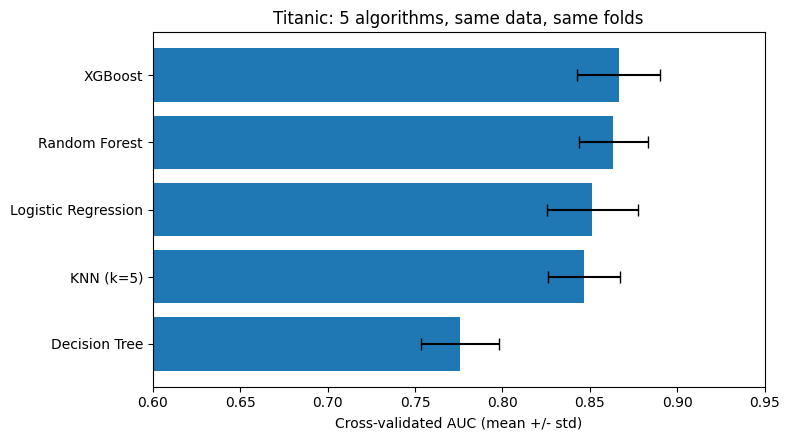

In [5]:
summary = pd.DataFrame({
    "mean": {k: v.mean() for k, v in results.items()},
    "std": {k: v.std() for k, v in results.items()},
}).sort_values("mean")

plt.figure(figsize=(8, 4.5))
plt.barh(summary.index, summary["mean"], xerr=summary["std"], color="#1f77b4", capsize=4)
plt.xlim(0.6, 0.95)
plt.xlabel("Cross-validated AUC (mean +/- std)")
plt.title("Titanic: 5 algorithms, same data, same folds")
plt.tight_layout()
plt.savefig("images/model_comparison_auc.png", dpi=150)
plt.show()

## Example 3: Is the ranking real, or noise?

In [6]:
# Same folds for every model, so we can compare fold by fold
best_two = summary.sort_values("mean", ascending=False).index[:2]
a, b = results[best_two[0]], results[best_two[1]]
diff = a - b

print("Top two:", best_two[0], "vs", best_two[1])
print("Mean AUC difference:", round(diff.mean(), 4))
print("Std of the differences:", round(diff.std(), 4))
print("Folds where the first one is better:", int((diff > 0).sum()), "out of", len(diff))

Top two: XGBoost vs Random Forest
Mean AUC difference: 0.0029
Std of the differences: 0.0129
Folds where the first one is better: 8 out of 15


## Example 4: Overfitting check (train AUC vs CV AUC)

In [7]:
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    out = cross_validate(pipe, X, y, cv=5, scoring="roc_auc", return_train_score=True)
    rows.append({
        "model": name,
        "train_auc": out["train_score"].mean(),
        "cv_auc": out["test_score"].mean(),
        "gap": out["train_score"].mean() - out["test_score"].mean(),
        "fit_sec": out["fit_time"].mean(),
    })
print(pd.DataFrame(rows).set_index("model").round(3))

                     train_auc  cv_auc    gap  fit_sec
model                                                 
Logistic Regression      0.857   0.848  0.009    0.009
KNN (k=5)                0.930   0.843  0.087    0.008
Decision Tree            0.999   0.775  0.225    0.009
Random Forest            0.998   0.855  0.142    0.330
XGBoost                  0.961   0.869  0.092    0.029


## Example 5: Feature importance (tree-based models)

In [8]:
# Fit each tree-based model on all the data to read its importances
importances = {}
for name in ["Decision Tree", "Random Forest", "XGBoost"]:
    pipe = Pipeline([("prep", preprocessor), ("model", models[name])]).fit(X, y)
    feature_names = pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=feature_names)
    importances[name] = imp / imp.sum()

imp_table = pd.DataFrame(importances)
imp_table.index = [i.split("__")[1] for i in imp_table.index]
top = imp_table.assign(avg=imp_table.mean(axis=1)).sort_values("avg", ascending=False)
print(top.drop(columns="avg").head(6).round(3))

            Decision Tree  Random Forest  XGBoost
Sex_female          0.311          0.136    0.422
Age                 0.237          0.256    0.028
Fare                0.234          0.250    0.029
Pclass_3            0.079          0.053    0.274
SibSp               0.051          0.046    0.057
Sex_male            0.000          0.146    0.000


               Decision Tree  Random Forest  XGBoost
Decision Tree           1.00           0.59     0.71
Random Forest           0.59           1.00     0.19
XGBoost                 0.71           0.19     1.00


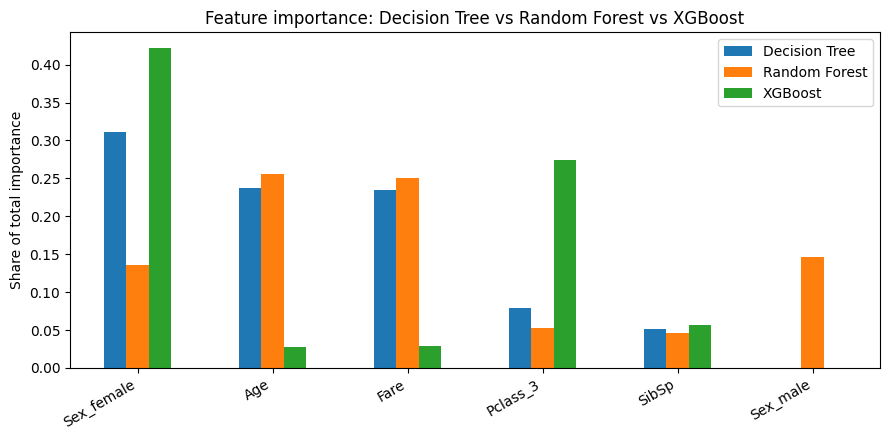

In [9]:
# Do the three models rank features the same way? (Spearman rank correlation)
print(imp_table.corr(method="spearman").round(2))

top6 = top.head(6).drop(columns="avg")
top6.plot(kind="bar", figsize=(9, 4.5))
plt.ylabel("Share of total importance")
plt.title("Feature importance: Decision Tree vs Random Forest vs XGBoost")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("images/feature_importance_comparison.png", dpi=150)
plt.show()

## Practice Exercise
Limit the Decision Tree to `max_depth=4`. Does its CV AUC go up, and does its train-vs-CV gap shrink?

In [10]:
shallow = Pipeline([("prep", preprocessor), ("model", DecisionTreeClassifier(max_depth=4, random_state=42))])
out = cross_validate(shallow, X, y, cv=5, scoring="roc_auc", return_train_score=True)
print("Depth 4 -> train AUC:", round(out["train_score"].mean(), 3), "| CV AUC:", round(out["test_score"].mean(), 3))
print("Unlimited depth -> CV AUC:", round(results["Decision Tree"].mean(), 3))

Depth 4 -> train AUC: 0.891 | CV AUC: 0.847
Unlimited depth -> CV AUC: 0.776


## Mini Challenge
Drop `Sex` from the features and rerun Random Forest. How much AUC is lost?

In [11]:
no_sex_cols = [c for c in categorical_cols if c != "Sex"]
prep_no_sex = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, no_sex_cols),
])
rf_no_sex = Pipeline([("prep", prep_no_sex), ("model", models["Random Forest"])])
no_sex = cross_val_score(rf_no_sex, X[numeric_cols + no_sex_cols], y, cv=cv, scoring="roc_auc")
print("Random Forest without Sex: AUC =", round(no_sex.mean(), 3))
print("Random Forest with Sex:    AUC =", round(results["Random Forest"].mean(), 3))

Random Forest without Sex: AUC = 0.755
Random Forest with Sex:    AUC = 0.864


## My Decision Guide
**Logistic Regression**
- I would use it when I need a fast, explainable baseline, or the data is small
- Because it scored 0.851, within noise of the best models, and had the smallest overfitting gap (0.009)

**KNN**
- I would use it when the data is small, has few features, and is scaled
- Because it scored 0.847 here, but it overfit more (gap 0.087) and gets slow and weak with many features

**Decision Tree**
- I would use it when I need rules I can draw and explain to anyone, and I limit its depth
- Because with no limit it memorized the training data (train AUC 0.999, CV 0.776), and depth 4 lifted CV AUC to 0.847

**Random Forest**
- I would use it as a strong default for tabular data with little tuning
- Because it scored 0.864 with the lowest spread (std 0.020), though it still shows a large train-vs-CV gap (0.142)

**XGBoost**
- I would use it when I want the last bit of accuracy and I can tune settings
- Because it scored highest (0.866), but only 0.003 above Random Forest, which is within noise, so on a small dataset like this I would not pick it on score alone

**My general rule**
- Start with Logistic Regression as a baseline, then try Random Forest, then XGBoost
- Keep the more complex model only if it beats the baseline by clearly more than the std


## Summary
- Same data, same preprocessing, same folds = a fair comparison
- Always read the std (and fold-by-fold differences), not just the mean
- Train-vs-CV gaps expose overfitting
- Tree-based models do not always agree on feature importance
- The best model on one dataset is not automatically the best everywhere